# Image Classification using CNN

At the end of this tutorial, you would get familiarized with

*   Creating deep networks using Keras
*   Steps necessary in training a neural network
*   Prediction and performance analysis using neural networks
*   Applying deeper convolutional architectures


**Remember this is a graded exercise.**

*   For every plot, make sure you provide appropriate titles, axis labels, legends, wherever applicable.
*   Create reusable functions where ever possible, so that the code could be reused at different places.
*   Add sufficient comments and explanations wherever necessary.
*   **Once you have the code completed, use GPU to train model faster.**

---

## Group
- Ecem Onat Cakmak  
- Michael Eskander  
- Pablo Longán Gasol

# Working with a CIFAR-10:

The CIFAR-10 dataset consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images. More information about CIFAR-10 can be found [here](https://www.cs.toronto.edu/~kriz/cifar.html).

In Keras, the CIFAR-10 dataset is also preloaded in the form of four Numpy arrays. x_train and y_train contain the training set, while x_test and y_test contain the test data. The images are encoded as Numpy arrays and their corresponding labels ranging from 0 to 9.

Your first task is to:
*   Visualize the images in CIFAR-10 dataset. Create a 10 x 10 plot showing 10 random samples from each class.


In [1]:


from tensorflow import keras
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print(tf.__version__)

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

2.22.0-rc0


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


In [2]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)


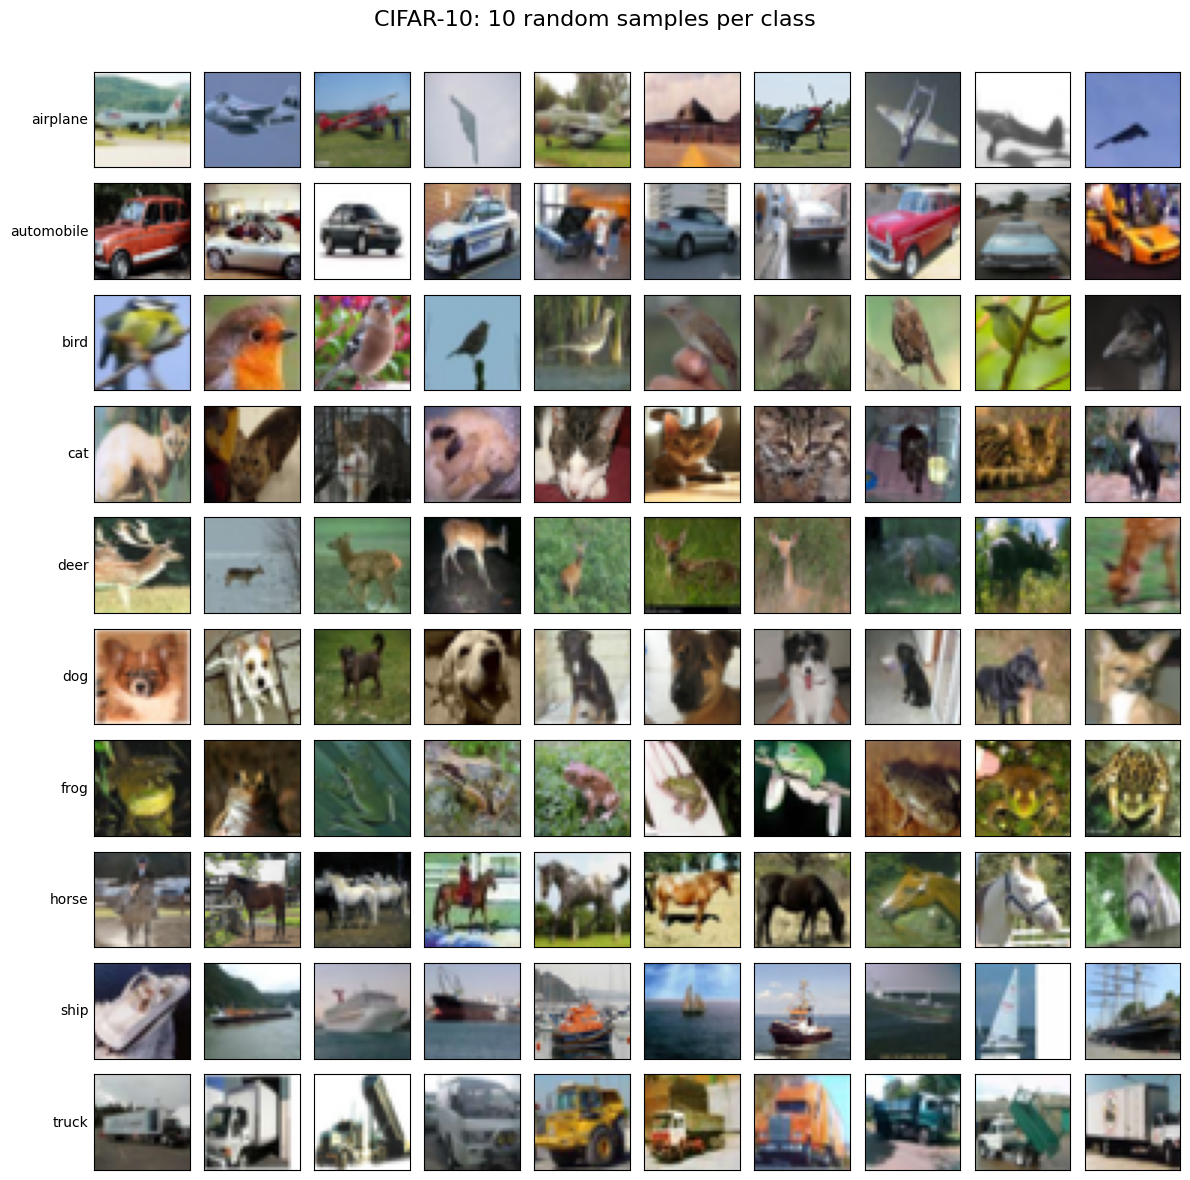

In [ ]:
#10 x 10 plot showing 10 random samples from each class
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]


def plot_class_samples(images, labels):
    # Support both integer labels and one-hot encoded labels.
    labels = np.asarray(labels)
    labels = labels.argmax(axis=1) if labels.ndim == 2 and labels.shape[1] > 1 else labels.ravel()
    rng = np.random.default_rng()
    fig, axes = plt.subplots(10, 10, figsize=(12, 12))

    for class_id, class_name in enumerate(class_names):
        indices = rng.choice(np.flatnonzero(labels == class_id), size=10, replace=False)
        for column, index in enumerate(indices):
            ax = axes[class_id, column]
            ax.imshow(images[index])
            ax.set_xticks([])
            ax.set_yticks([])
            if column == 0:
                ax.set_ylabel(class_name, rotation=0, ha="right", va="center")

    fig.suptitle("CIFAR-10: 10 random samples per class", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


plot_class_samples(x_train, y_train)


The plot_class_samples function displays 10 random images from each of the 10 CIFAR-10 classes in a 10 × 10 grid, with one class per row.  

CIFAR-10 uses the following standard label order:  

0: airplane,  
1: automobile,  
2: bird,  
3: cat,  
4: deer,  
5: dog,  
6: frog,  
7: horse,  
8: ship,  
9: truck  

The class_names list was manually defined using this mapping. The names are not inferred from the images; Keras’s load_data() returns images and numeric labels.
The function converts the labels into a flat array of class IDs, using argmax if they are one-hot encoded. For each class, np.flatnonzero finds the corresponding image positions, and the random number generator selects 10 positions. Setting replace=False ensures that each selected image appears only once within its row.  

The images are displayed using imshow. Tick marks are removed, each row is labeled with its class name, and a title is added. Finally, the spacing is adjusted before displaying the figure.  

Calling plot_class_samples(x_train, y_train) creates the grid from the training data. Each execution produces a new random selection without modifying the original data.

*   Convert the labels to one-hot encoded form.
*   Normalize the images.

In [4]:
# Convert class labels (0–9) into one-hot vectors of length 10
y_train = keras.utils.to_categorical(y_train, num_classes=10)
y_test = keras.utils.to_categorical(y_test, num_classes=10)

# Normalizing the images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Check the results
print("Label shapes:", y_train.shape, y_test.shape)
print("Example encoded label:", y_train[0])
print("Training pixel range:", x_train.min(), x_train.max())

Label shapes: (50000, 10) (10000, 10)
Example encoded label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
Training pixel range: 0.0 1.0


Normalized the images by converting pixel values to float32 and dividing by 255. This rescales each RGB channel from [0, 255] to [0, 1], preserving the image information while providing a suitable input scale for model training.

**Adding an additional split for validation:**

For this dataset, we will further split train set into two, so we can have an unseen dataset to validate results during the training process. Your task is to:


*   Use the function train_test_split from sklearn.model_selection to further split the training set
*   Assign 10% of training to validation set, the rest should remain as training.
*   Print the shape of train, validation and test set



In [5]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=np.argmax(y_train, axis=1)
)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Training: (45000, 32, 32, 3) (45000, 10)
Validation: (5000, 32, 32, 3) (5000, 10)
Test: (10000, 32, 32, 3) (10000, 10)


## Define the following model (same as the one used for MNIST)

**For the convolutional front-end, start with a single convolutional layer with a small filter size (3,3) and a modest number of filters (32) followed by a max pooling layer. Use the right input shape given the data shape seen above. The filter maps can then be flattened to provide features to the classifier. Use a dense layer with 100 units before the classification layer (which is also a dense layer with softmax activation).*

In [6]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

# Build the model layer by layer
model = Sequential()

# Apply 32 filters of size 3 × 3 to 32 × 32 RGB images
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))

# Reduce the feature maps using 2 × 2 max pooling
model.add(MaxPooling2D((2, 2)))

# Flatten the feature maps into a vector
model.add(Flatten())

# Add a fully connected layer with 100 neurons
model.add(Dense(100, activation='relu'))

# Output probabilities for the 10 classes
model.add(Dense(10, activation='softmax'))

model.summary()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       720,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 722,006 (2.75 MB)

 Trainable params: 722,006 (2.75 MB)

 Non-trainable params: 0 (0.00 B)

Defined a CNN with one convolutional layer containing 32 filters of size 3 × 3, followed by 2 × 2 max pooling. The feature maps are flattened and passed to a dense layer with 100 units. The final softmax layer outputs probabilities for the 10 CIFAR-10 classes.

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train over this dataset and train the model for 50 epochs with a batch size of 32.
*   Make sure to include the validation set in the fit function

In [7]:
# Compile: loss, optimizer and metric
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Train for 50 epochs, batch size 32, using the validation set
n_epochs = 50
history = model.fit(x_train, y_train, batch_size=32, epochs=n_epochs,
                    validation_data=(x_val, y_val))

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3223 - loss: 1.9091 - val_accuracy: 0.2758 - val_loss: 2.1035
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4355 - loss: 1.6000 - val_accuracy: 0.4038 - val_loss: 1.7007
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5048 - loss: 1.4029 - val_accuracy: 0.4986 - val_loss: 1.4161
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5438 - loss: 1.2952 - val_accuracy: 0.5278 - val_loss: 1.3268
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5717 - loss: 1.2232 - val_accuracy: 0.5410 - val_loss: 1.2842
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5918 - loss: 1.1668 - val_accuracy: 0.5534 - val_loss: 1.2553
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6112 - loss: 1.1170 - val_accuracy: 0.5608 - val_loss: 1.2378
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6273 - loss: 1.0708 - 

* Plot the train and validation loss by epoch
* Plot the train and validation accuracy by epoch

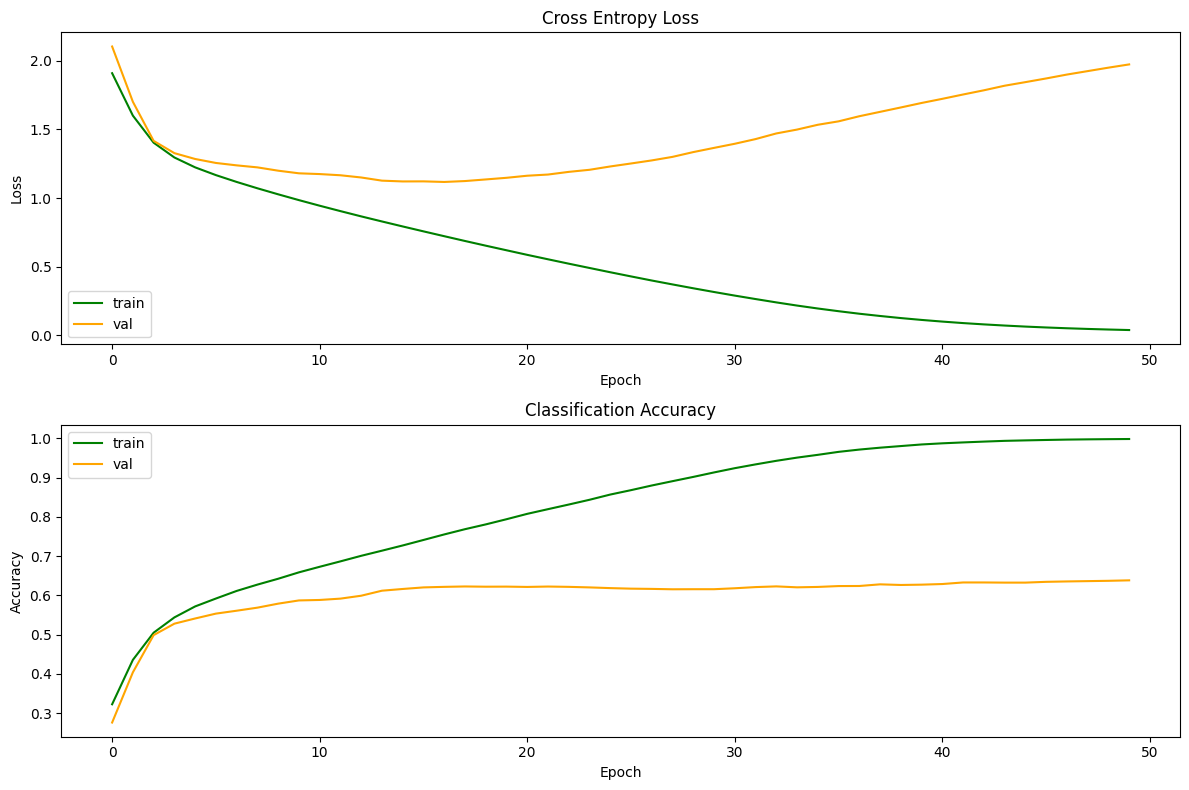

In [8]:
plt.figure(figsize=(12, 8))

plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history.history['loss'], color='green', label='train')
plt.plot(history.history['val_loss'], color='orange', label='val')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history.history['accuracy'], color='green', label='train')
plt.plot(history.history['val_accuracy'], color='orange', label='val')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

What is the advantage of having a validation set? Why is the validation accuracy lower than the training set? Can you explain the effect on validation loss and why does it decrease and then increase?

**Solution**

*   **Advantage of a validation set:** it is data the model does not train on. It shows how well the model works on new images, so we can spot overfitting without using the test set.
*   **Validation accuracy < training accuracy:** the model's weights are optimized directly on the training images,so accuracy is lower on new data.
*   **Validation loss decreases, then increases:** at first the model learns general patterns, so both losses go down. After about epoch 18, the model starts memorizing the training images (overfitting). The training loss keeps going down, but the validation loss goes up because the model does worse on new images

*   Use predict function to predict the output for the **test** set
*   Plot the confusion matrix for the new model and comment on the class confusions.


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 921us/step


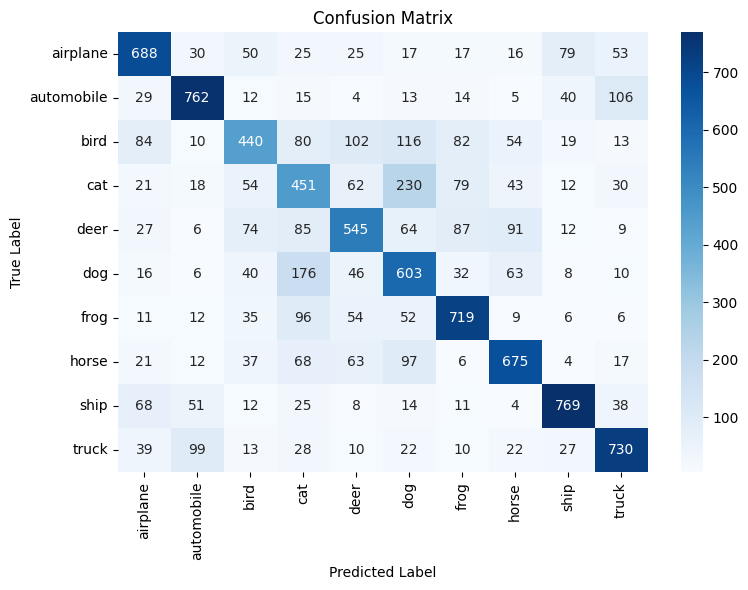

              precision    recall  f1-score   support

    airplane       0.69      0.69      0.69      1000
  automobile       0.76      0.76      0.76      1000
        bird       0.57      0.44      0.50      1000
         cat       0.43      0.45      0.44      1000
        deer       0.59      0.55      0.57      1000
         dog       0.49      0.60      0.54      1000
        frog       0.68      0.72      0.70      1000
       horse       0.69      0.68      0.68      1000
        ship       0.79      0.77      0.78      1000
       truck       0.72      0.73      0.73      1000

    accuracy                           0.64     10000
   macro avg       0.64      0.64      0.64     10000
weighted avg       0.64      0.64      0.64     10000



In [9]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Predict on the test set (probabilities -> class index)
predictions = np.argmax(model.predict(x_test), axis=1)

# Ground truth labels (one-hot -> class index)
gt = np.argmax(y_test, axis=1)

# Confusion matrix
cm = confusion_matrix(gt, predictions)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

# Per-class precision, recall and F1-score
print(classification_report(gt, predictions, target_names=class_names))

Your comments here:

**Solution**

*   The diagonal holds the correct predictions (overall accuracy 64%). The biggest confusions are between visually similar classes: dog and cat , truck and automobile , ship and airplane. Ship (0.77) automobile (0.73) are recognized best , while cat (0.45) and bird (0.56) are worst.
* A single conv layer only captures low-level features such as edges, colors and textures, so it cannot separate these similar animals and vehicles.

Print the test accuracy for the trained model.

In [10]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 960us/step - accuracy: 0.6382 - loss: 1.9921
Test loss: 1.9920789003372192
Test accuracy: 0.6381999850273132


The test accuracy is 63.82%, similar to the validation accuracy, which confirms that the validation set gave us a good estimate of the performance on new data.

This is much better than random guessing (10% with 10 classes), but there is still room for improvement

## Defining Deeper Architectures: VGG Models

*   Define a deeper model architecture for the dataset and train the new model for 50 epochs with a batch size of 32. We will use VGG model as the architecture.
*   Make sure to include your validation set in the training process in the appropriate way.

**Stack two convolutional layers with 32 filters, each of 3 x 3. Use a max pooling layer and next flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**

In [11]:
from keras.backend import clear_session
clear_session()

In [12]:
# VGG-style model: two convolutional layers stacked before pooling
model_vgg = Sequential()

# Two convolutional layers with 32 filters of size 3x3
# padding='same' keeps the height and width of the image (32x32)
model_vgg.add(Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)))
model_vgg.add(Conv2D(32, (3, 3), activation='relu', padding='same'))

# Reduce the size of the feature maps with 2x2 max pooling
model_vgg.add(MaxPooling2D((2, 2)))

# Flatten the feature maps into a vector
model_vgg.add(Flatten())

# Fully connected layer with 128 neurons
model_vgg.add(Dense(128, activation='relu'))

# Output layer: probabilities for the 10 classes
model_vgg.add(Dense(10, activation='softmax'))

model_vgg.summary()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,060,138 (4.04 MB)

 Trainable params: 1,060,138 (4.04 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train the model for 50 epochs with a batch size of 32.
*   Include the validation set in the fit function
*   Plot loss and accuracy for train and validation


In [13]:
# Compile the VGG model with the same settings as before
model_vgg.compile(loss='categorical_crossentropy',
                  optimizer='sgd',
                  metrics=['accuracy'])

# Train for 50 epochs with batch size 32, using the validation set
history_vgg = model_vgg.fit(x_train, y_train,
                            epochs=50,
                            batch_size=32,
                            validation_data=(x_val, y_val))

# Plot loss and accuracy for train and validation
def plot_history(history, title="Model"):
    epochs = range(1, len(history.history['loss']) + 1)

    plt.figure(figsize=(12, 4))
plot_history(history_vgg, title="VGG")

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.3372 - loss: 1.8617 - val_accuracy: 0.2896 - val_loss: 2.0738
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.4600 - loss: 1.5175 - val_accuracy: 0.4480 - val_loss: 1.5609
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.5286 - loss: 1.3299 - val_accuracy: 0.5028 - val_loss: 1.3919
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.5754 - loss: 1.2027 - val_accuracy: 0.5302 - val_loss: 1.3020
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.6122 - loss: 1.1030 - val_accuracy: 0.5466 - val_loss: 1.2705
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.6444 - loss: 1.0171 - val_accuracy: 0.5550 - val_loss: 1.2556
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.6713 - loss: 0.9399 - val_accuracy: 0.5620 - val_loss: 1.2491
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.6985 - lo

<Figure size 1200x400 with 0 Axes>

*   Use predict function to predict the output for the test split
*   Plot the confusion matrix for the new model and comment on the class confusions.


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


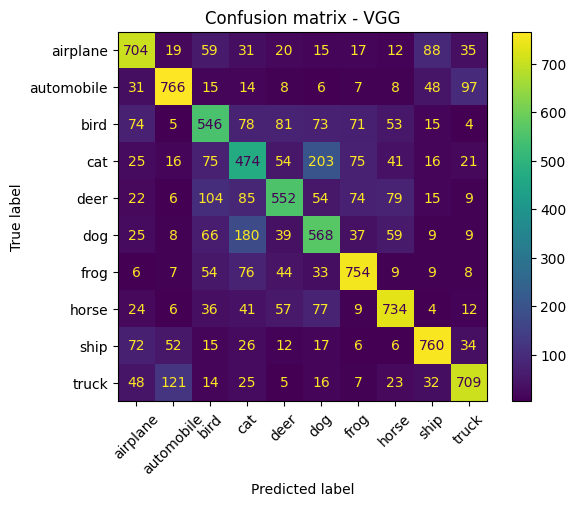

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

# Predict the test set with the VGG model
y_pred_vgg = np.argmax(model_vgg.predict(x_test), axis=1)
y_true = np.argmax(y_test, axis=1)

# Plot the confusion matrix 
cm_vgg = confusion_matrix(y_true, y_pred_vgg)
disp = ConfusionMatrixDisplay(cm_vgg, display_labels=class_names)
disp.plot(xticks_rotation=45)
plt.title('Confusion matrix - VGG')
plt.show()

*    Print the test accuracy for the trained model.

In [17]:
# Evaluate the VGG model on the test set
test_loss_vgg, test_acc_vgg = model_vgg.evaluate(x_test, y_test)
print("Test accuracy (VGG):", test_acc_vgg)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6567 - loss: 3.0856
Test accuracy (VGG): 0.6567000150680542


The VGG model achieves 65.67% accuracy, compared with 63.82% for the original CNN, improving accuracy by 1.85 percentage points.  

The largest improvements occur for birds, with correct predictions increasing from 440 to 546, and horses, increasing from 675 to 734. VGG also improves recognition of airplanes, automobiles, cats, deer, and frogs. However, correct predictions decrease for dogs (603 → 568), ships (769 → 760), and trucks (730 → 709).  

Cats and dogs remain the main source of confusion. VGG reduces cats incorrectly classified as dogs from 230 to 203, but dogs classified as cats increase slightly from 176 to 180.  

Confusion between automobiles and trucks also persists.  

Overall, VGG provides a modest improvement, particularly for birds and horses, but its deeper architecture does not improve every class.

# Understanding deep networks

*   What is the use of activation functions in network? Why is it needed?
*   We have used softmax activation function in the exercise. There are other activation functions available too. What is the difference between sigmoid activation and softmax activation?
*   What is the difference between categorical crossentropy and binary crossentropy loss?

**Solution**

Activation functions are applied to the output of each neuron. They add non-linearity to the network. Without them, all the layers would only do linear operations (multiplications and sums), so the whole network would be equivalent to a single linear model, no matter how many layers it has. This means it could not learn complex patterns like the shapes and objects in images. In our models we used ReLU in the hidden layers, which sets negative values to 0 and keeps positive values, and softmax in the output layer.

Sigmoid transforms each output into a value between 0 and 1, but each output is independent, so the values do not have to add up to 1. It is used for binary classification (two classes, for example sick or healthy) or when an image can belong to more than one class at the same time. Softmax transforms all the outputs together into probabilities that add up to 1, so it chooses one class among several. That is why we used softmax in our models, because each CIFAR-10 image belongs to only one of the 10 classes.

Binary crossentropy is used when there are only two classes, usually together with a sigmoid output. Categorical crossentropy is used when there are more than two classes and the labels are one-hot encoded, usually together with softmax. Both measure how far the predicted probabilities are from the real labels, and the loss is higher when the model gives a low probability to the correct class. In this lab we used categorical crossentropy because CIFAR-10 has 10 classes.


---

# **End of Lab 02: Image Classification using CNN**
Deadline for submission is: **22/10/2026**